# output.ipynb — Mục 4.2.2: Suy luận Bayesian CPT và ANFIS rule học được
## Thực nghiệm 1 — A2_soft_exp1

Notebook này đọc trực tiếp artifact JSON của thực nghiệm 1 (**không chạy lại training**) và sinh các biểu đồ phục vụ mục 4.2 của khóa luận:
- Cấu trúc Bayesian Network
- CPT heatmap (log-likelihood ratio)
- Raw CPT grouped bars
- Sample BN inference trace
- ANFIS rule importance heatmap

---
## Phần 1 — Load experiment artifacts

In [ ]:
"""
Phần 1: Load experiment artifacts từ folder A2_soft_exp1.
Không chạy lại training. Chỉ đọc JSON artifact đã có sẵn.
"""
import json
import re
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

# ---------------------------------------------------------------
# Đường dẫn artifact — dùng pathlib để tương thích Kaggle/Linux
# ---------------------------------------------------------------
# Notebook này nằm ở gốc project; artifact nằm trong:
#   artifacts/A2_soft_exp1/
# Nếu chạy trên Kaggle, sửa ROOT cho phù hợp.
ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

EXP_NAME = "A2_soft_exp1"

# Updated path: no double nesting (fixed May 20, 2026)
EXP_DIR = ROOT / "artifacts" / EXP_NAME

REQUIRED_FILES = {
    "bn_details": EXP_DIR / "bn_details.json",
    "anfis_rules": EXP_DIR / "anfis_rules.json",
}

# Kiểm tra file tồn tại — báo lỗi rõ ràng thay vì silent fail
missing = [name for name, path in REQUIRED_FILES.items() if not path.exists()]
if missing:
    raise FileNotFoundError(
        f"[ERROR] Các file artifact sau không tìm thấy trong {EXP_DIR}:\n"
        + "\n".join(f"  - {name}: {REQUIRED_FILES[name]}" for name in missing)
    )

# Load JSON
with open(REQUIRED_FILES["bn_details"], encoding="utf-8") as f:
    bn_details = json.load(f)

with open(REQUIRED_FILES["anfis_rules"], encoding="utf-8") as f:
    anfis_rules = json.load(f)

# ---------------------------------------------------------------
# In summary
# ---------------------------------------------------------------
cfg = bn_details["configuration"]
metrics = bn_details["test_metrics"]
bn_struct = bn_details["bn_structure"]

print("=" * 60)
print(f"Experiment  : {bn_details['experiment']}")
print(f"Threshold   : {bn_details['threshold']}")
print(f"Test metrics: acc={metrics['acc']:.4f}  bal_acc={metrics['bal_acc']:.4f}"
      f"  macro_f1={metrics['macro_f1']:.4f}  AUC={metrics['auc']:.4f}")
print(f"BN root     : {bn_struct['root']}  states={bn_struct['root_states']}")
print(f"Evidence    : {bn_struct['evidence_nodes']}")
print(f"n_bins      : {bn_struct['n_bins']}  bin_names={bn_struct['bin_names']}")
print("=" * 60)

# Tạo thư mục output
FIG_DIR = EXP_DIR / "figures_4_2"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"Output dir  : {FIG_DIR}")

---
## Phần 2 — Figure: Cấu trúc Bayesian Network

In [ ]:
"""
Phần 2: Vẽ sơ đồ cấu trúc Bayesian Network.
Dùng matplotlib patches — không cần pyAgrum, chạy được trên Kaggle.
"""

prior = bn_details["prior"]
evidence_nodes = bn_struct["evidence_nodes"]   # ['Temp', 'HR', 'GSR', 'RR']
bin_names = bn_struct["bin_names"]

fig, ax = plt.subplots(figsize=(9, 5))
ax.set_xlim(0, 10)
ax.set_ylim(0, 6)
ax.axis("off")

# Hàm helper vẽ node tròn với text
def draw_node(ax, cx, cy, label, sub="", color="#4C72B0", fontsize=11):
    circle = plt.Circle((cx, cy), 0.72, color=color, zorder=3)
    ax.add_patch(circle)
    ax.text(cx, cy + (0.18 if sub else 0), label,
            ha="center", va="center", fontsize=fontsize,
            fontweight="bold", color="white", zorder=4)
    if sub:
        ax.text(cx, cy - 0.3, sub, ha="center", va="center",
                fontsize=7.5, color="#f0f0f0", zorder=4)

# Hàm helper vẽ mũi tên
def draw_arrow(ax, x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", lw=1.8, color="#333333"),
                zorder=2)

# ----- Root node CL -----
cl_x, cl_y = 5.0, 4.6
draw_node(ax, cl_x, cl_y, "CL",
          f"P(rest)={prior['rest']:.3f}\nP(task)={prior['task']:.3f}",
          color="#c0392b", fontsize=12)

# ----- Evidence nodes -----
ev_positions = {
    "Temp": (1.8, 2.0),
    "HR":   (4.0, 2.0),
    "GSR":  (6.0, 2.0),
    "RR":   (8.2, 2.0),
}
ev_colors = {"Temp": "#2980b9", "HR": "#27ae60", "GSR": "#8e44ad", "RR": "#e67e22"}

for sig, (ex, ey) in ev_positions.items():
    draw_node(ax, ex, ey, sig, color=ev_colors[sig], fontsize=11)
    # Vẽ mũi tên từ CL xuống evidence
    draw_arrow(ax, cl_x, cl_y - 0.72, ex, ey + 0.72)

# ----- Chú thích bins -----
bins_str = ", ".join(bin_names)
ax.text(5.0, 0.9, f"Evidence bins: {bins_str}",
        ha="center", va="center", fontsize=9, color="#555555",
        style="italic")
ax.text(5.0, 0.4, "CL ∈ {rest, task}",
        ha="center", va="center", fontsize=9, color="#555555",
        style="italic")

ax.set_title("Cấu trúc Bayesian Network Fusion — Thực nghiệm 1 (A2_soft_exp1)",
             fontsize=13, pad=12)

fig.tight_layout()
out_path = FIG_DIR / "fig_bn_structure.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[saved] {out_path}")

---
## Phần 3 — Figure: CPT Log-Likelihood Ratio Heatmap

In [ ]:
"""
Phần 3: CPT Log-Likelihood Ratio heatmap.
LLR(s, b) = log( P(E_s=b | task) / P(E_s=b | rest) )
- Giá trị dương: bin b ủng hộ lớp TASK
- Giá trị âm: bin b ủng hộ lớp REST
"""
cpt = bn_details["cpt_tables"]   # dict: signal -> {rest: {bin: p}, task: {bin: p}}
signals = evidence_nodes          # ['Temp', 'HR', 'GSR', 'RR']

# Tính LLR cho mỗi (signal, bin)
llr_data = {}
for sig in signals:
    llr_data[sig] = {}
    for b in bin_names:
        p_task = cpt[sig]["task"][b]
        p_rest = cpt[sig]["rest"][b]
        # Clip tránh log(0)
        llr_data[sig][b] = np.log(np.maximum(p_task, 1e-9) / np.maximum(p_rest, 1e-9))

# Tạo DataFrame — hàng: signal, cột: bin
df_llr = pd.DataFrame(llr_data, index=bin_names).T  # (n_signals, n_bins)
df_llr.index.name = "Signal"
df_llr.columns.name = "Bin"

# Lưu CSV
csv_path = FIG_DIR / "cpt_log_likelihood_ratio.csv"
df_llr.to_csv(csv_path)
print(f"[saved] {csv_path}")
print(df_llr.round(4))

# ---- Vẽ heatmap bằng matplotlib imshow ----
fig, ax = plt.subplots(figsize=(8, 3.5))
mat = df_llr.values.astype(float)    # (4, 5)
vmax = np.abs(mat).max()

im = ax.imshow(mat, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")

# Trục
ax.set_xticks(range(len(bin_names)))
ax.set_xticklabels(bin_names, fontsize=10)
ax.set_yticks(range(len(signals)))
ax.set_yticklabels(signals, fontsize=10)
ax.set_xlabel("Evidence bin", fontsize=10)
ax.set_ylabel("Tín hiệu sinh lý", fontsize=10)
ax.set_title("CPT Log-Likelihood Ratio  LLR(s,b) = log P(b|task) / P(b|rest)\n"
             "Dương → ủng hộ TASK   |   Âm → ủng hộ REST", fontsize=10)

# Annotate giá trị
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        val = mat[i, j]
        color = "white" if abs(val) > 0.5 * vmax else "black"
        ax.text(j, i, f"{val:+.3f}", ha="center", va="center",
                fontsize=9, color=color, fontweight="bold")

plt.colorbar(im, ax=ax, label="LLR")
fig.tight_layout()
out_path = FIG_DIR / "fig_cpt_llr_heatmap.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[saved] {out_path}")

---
## Phần 4 — Figure: Raw CPT Grouped Bars (mỗi tín hiệu một figure)

In [ ]:
"""
Phần 4: Grouped bar chart P(bin | class) cho mỗi tín hiệu.
Mỗi hình là một tín hiệu với hai nhóm bar: rest và task.
"""
bar_width = 0.35
x = np.arange(len(bin_names))

for sig in signals:
    p_rest = np.array([cpt[sig]["rest"][b] for b in bin_names])
    p_task = np.array([cpt[sig]["task"][b] for b in bin_names])

    fig, ax = plt.subplots(figsize=(7, 4))

    bars_rest = ax.bar(x - bar_width / 2, p_rest, bar_width,
                       label="REST", color="#3498db", alpha=0.85)
    bars_task = ax.bar(x + bar_width / 2, p_task, bar_width,
                       label="TASK", color="#e74c3c", alpha=0.85)

    # Annotate giá trị xác suất lên bar
    for bar in bars_rest:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.005,
                f"{h:.3f}", ha="center", va="bottom", fontsize=7.5)
    for bar in bars_task:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.005,
                f"{h:.3f}", ha="center", va="bottom", fontsize=7.5)

    ax.set_xticks(x)
    ax.set_xticklabels(bin_names, fontsize=10)
    ax.set_ylim(0, max(p_rest.max(), p_task.max()) * 1.25)
    ax.set_xlabel("Evidence bin", fontsize=10)
    ax.set_ylabel("P(bin | class)", fontsize=10)
    ax.set_title(f"CPT của tín hiệu {sig}: P(bin | class)", fontsize=11)
    ax.legend(fontsize=10)

    fig.tight_layout()
    out_path = FIG_DIR / f"fig_cpt_{sig}.png"
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"[saved] {out_path}")

---
## Phần 5 — Figure: Sample BN Inference Trace

In [3]:
%run ../main.py --ablation exp1 --preset A2_soft

FBN PIPELINE - MAIN RUNNER
Project root : C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final
Data folder  : C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\last_30s_segments
Preset       : A2_soft
Ablation     : exp1
Experiment   : A2_soft_exp1
Artifacts dir : C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1
Train: X=(632, 4, 30), y=(632,), users=(632,)  user_ids=['1mpau', '2nxs5', '5gpsc', '7swyk', '8a1ep', 'b7mrd', 'c24ur', 'dkhty', 'e4gay', 'ef5rq', 'f3j25', 'hpbxa', 'ibvx8', 'iz2ps', 'rc1in', 'tn4vl', 'wjxci', 'yljm5']
Test : X=(193, 4, 30), y=(193,), users=(193,)  user_ids=['3caqi', '6frz4', 'bd47a', 'f1gjp', 'iz3x1']

  PIPELINE CONFIGURATION
  seed                               : 42
  k_folds                            : 5
  data_path                          : last_30s_segments
  n_sets                             : 3
  mf_type                            : gaussian
  mf_sigma_scale                     : 0.4
 

[reload] bn_details loaded from artifact JSON
[reload] signals = ['Temp', 'HR', 'GSR', 'RR']
Soft memberships:
  Temp : very_low=0.0046, low=0.3299, med=0.3272, high=0.3144, very_high=0.0239
  HR   : very_low=0.0002, low=0.1942, med=0.3019, high=0.4000, very_high=0.1037
  GSR  : very_low=0.0001, low=0.2493, med=0.2914, high=0.3190, very_high=0.1402
  RR   : very_low=0.0000, low=0.0366, med=0.1858, high=0.3634, very_high=0.4142



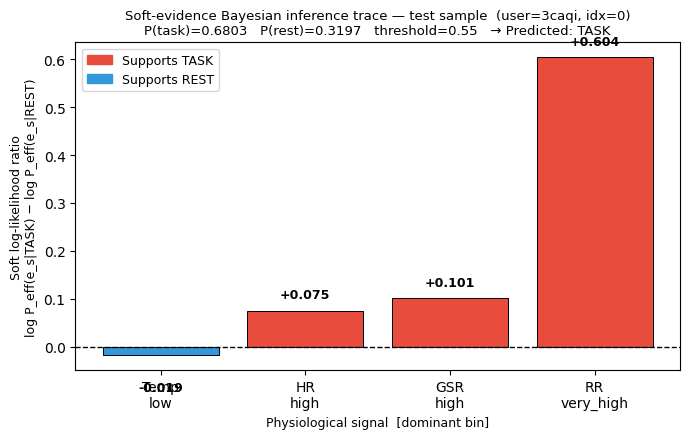

[saved] C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_sample_bayesian_prediction.png
[saved] C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\sample_bn_inference_trace.csv
Trace mode       : soft
Resolved mode    : soft
BN soft evidence : True
Has soft trace   : True
Has soft params  : True
Posterior source : stored (predict_proba)
Sample index     : 0
User ID          : 3caqi
Final P(TASK)    : 0.6803
Final P(REST)    : 0.3197
Threshold        : 0.5500
Predicted        : TASK

Signal Dominant_bin       LLR mode  sample_index user_id  final_p_task  final_p_rest  threshold predicted
  Temp          low -0.018664 soft             0   3caqi      0.680279      0.319721       0.55      TASK
    HR         high  0.074691 soft             0   3caqi      0.680279      0.319721       0.55      TASK
   GSR         high  0.101030 soft             0   3caqi      0.680279      0.319721      

In [4]:
"""
Figure 4.5 — Soft-evidence Bayesian Inference Trace (final posterior).

In the main experiment A2_soft (bn_soft=True), each ANFIS output p_s is NOT
assigned to a single hard bin.  Instead it is mapped to a Gaussian-kernel
membership vector over all bins:

    μ_{s,b}(p_s)

The effective likelihood for each signal is then:

    P_eff(e_s | C=c) = Σ_b  μ_{s,b}(p_s) · P(E_s=b | C=c)

The bar chart shows the soft log-likelihood ratio:

    LLR(s) = w_s·log P_eff(e_s|TASK) − w_s·log P_eff(e_s|REST)

Positive → supports TASK; negative → supports REST.

Bin labels on the x-axis are the DOMINANT bin (argmax membership) and are
used only for visualization — they are NOT the actual evidence in inference.

This cell works with both:
  - New artifacts (trace has "mode", "log_likelihood_ratio", "soft_memberships")
  - Old artifacts (no "mode" key) — computes soft LLR on-the-fly from
    anfis_probs + bin_mids + bin_sigmas stored in bn_structure.
"""

# ---------------------------------------------------------------
# Self-contained reload guard — %run main.py resets the namespace
# ---------------------------------------------------------------
import json as _json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

try:
    bn_details
except NameError:
    _ROOT = Path.cwd().resolve()
    if _ROOT.name == "notebooks":
        _ROOT = _ROOT.parent
    _EXP_DIR = _ROOT / "artifacts" / "A2_soft_exp1"
    with open(_EXP_DIR / "bn_details.json", encoding="utf-8") as _f:
        bn_details = _json.load(_f)
    print("[reload] bn_details loaded from artifact JSON")

try:
    signals
except NameError:
    signals = bn_details["bn_structure"]["evidence_nodes"]
    print(f"[reload] signals = {signals}")

try:
    FIG_DIR
except NameError:
    _ROOT = Path.cwd().resolve()
    if _ROOT.name == "notebooks":
        _ROOT = _ROOT.parent
    FIG_DIR = _ROOT / "artifacts" / "A2_soft_exp1" / "figures_4_2"
    FIG_DIR.mkdir(parents=True, exist_ok=True)

trace      = bn_details["sample_inference_trace"]
threshold  = bn_details["threshold"]
cpt        = bn_details["cpt_tables"]
prior      = bn_details["prior"]
sw         = bn_details.get("signal_weights", {s: 1.0 for s in signals})
bn_struct  = bn_details["bn_structure"]

sample_idx = trace.get("sample_index", 0)
user_id    = trace.get("user_id", "unknown")

has_soft_trace = (
    trace.get("mode") == "soft"
    and "soft_memberships" in trace
    and "log_likelihood_ratio" in trace
    and "effective_likelihoods" in trace
)

has_soft_params = (
    "anfis_probs" in trace
    and bn_struct.get("bin_mids") is not None
    and bn_struct.get("bin_sigmas") is not None
)

if has_soft_trace:
    mode = "soft"
elif bn_struct.get("soft_evidence", False) and has_soft_params:
    mode = "soft"
else:
    mode = "hard"

# Strict guard: if artifact says soft but we resolved hard, abort early
if bn_struct.get("soft_evidence", False) and mode == "hard":
    raise RuntimeError(
        "This artifact says soft_evidence=True, but the figure is using hard mode. "
        "The sample trace is stale or missing soft fields. "
        "Re-run main.py / regenerate bn_details.json."
    )

# ---------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------

def _soft_posterior_from_json(anfis_probs, cpt, bin_names, prior, weights, bin_mids, bin_sigmas):
    """Reproduce predict_proba (soft-evidence) entirely from JSON data."""
    log_p = np.array([np.log(prior["rest"] + 1e-10), np.log(prior["task"] + 1e-10)])
    for sig in anfis_probs:
        p_val  = anfis_probs[sig]
        mids   = np.array(bin_mids[sig])
        sigma  = bin_sigmas[sig]
        w      = weights.get(sig, 1.0)
        mem    = np.exp(-0.5 * ((p_val - mids) / (sigma + 1e-10)) ** 2)
        mem   /= mem.sum() + 1e-10
        for c_idx, cls in enumerate(["rest", "task"]):
            cpt_vals = np.array([cpt[sig][cls][b] for b in bin_names])
            p_ev = float(np.dot(mem, cpt_vals))
            log_p[c_idx] += w * np.log(p_ev + 1e-10)
    log_p -= log_p.max()
    p = np.exp(log_p); p /= p.sum()
    return float(p[1])


def _compute_soft_llr_from_json(anfis_probs, cpt, bin_names, weights, bin_mids, bin_sigmas):
    """
    Compute soft LLR, soft memberships and effective likelihoods from JSON.
    Used when trace was saved by old code (no 'log_likelihood_ratio' key).
    """
    llr, memberships = {}, {}
    eff_likelihoods = {"rest": {}, "task": {}}
    for sig in anfis_probs:
        p_val  = anfis_probs[sig]
        mids   = np.array(bin_mids[sig])
        sigma  = bin_sigmas[sig]
        w      = weights.get(sig, 1.0)
        mem    = np.exp(-0.5 * ((p_val - mids) / (sigma + 1e-10)) ** 2)
        mem   /= mem.sum() + 1e-10
        memberships[sig] = {b: float(mem[i]) for i, b in enumerate(bin_names)}
        ll_vals = []
        for c_idx, cls in enumerate(["rest", "task"]):
            cpt_vals = np.array([cpt[sig][cls][b] for b in bin_names])
            p_ev = float(np.dot(mem, cpt_vals))
            eff_likelihoods[cls][sig] = p_ev
            ll_vals.append(w * np.log(p_ev + 1e-10))
        llr[sig] = ll_vals[1] - ll_vals[0]   # task - rest
    return llr, memberships, eff_likelihoods

# ---------------------------------------------------------------
# Resolve final posterior — three-tier priority
# ---------------------------------------------------------------
if "final_posterior_task" in trace:
    post_task_final = trace["final_posterior_task"]
    _source = "stored (predict_proba)"
elif ("anfis_probs" in trace
      and bn_struct.get("bin_mids") is not None
      and bn_struct.get("bin_sigmas") is not None):
    post_task_final = _soft_posterior_from_json(
        trace["anfis_probs"], cpt, bn_struct["bin_names"],
        prior, sw, bn_struct["bin_mids"], bn_struct["bin_sigmas"],
    )
    _source = "recomputed (soft, from anfis_probs+bin_mids)"
else:
    post_task_final = trace["posterior_task"]
    _source = "FALLBACK hard-bin — re-run main.py to get correct value"
    print(f"[WARN] Using hard-bin posterior ({post_task_final:.4f}). "
          "Re-run main.py then reload artifacts to get soft-evidence posterior.")

post_rest_final = 1.0 - post_task_final
predicted = "TASK" if post_task_final >= threshold else "REST"

# ---------------------------------------------------------------
# Compute contributions / LLR for the bar chart
# ---------------------------------------------------------------
if mode == "soft":
    if "log_likelihood_ratio" in trace:
        # New artifact: soft fields already present in trace
        contributions  = {sig: trace["log_likelihood_ratio"][sig] for sig in signals}
        dom_bins       = trace.get("dominant_bins", trace.get("evidence_bins", {}))
        sm             = trace.get("soft_memberships", {})
        eff            = trace.get("effective_likelihoods", {})
    else:
        # Old artifact: compute on-the-fly from anfis_probs + bin_mids/sigmas
        contributions, sm, eff = _compute_soft_llr_from_json(
            trace["anfis_probs"], cpt, bn_struct["bin_names"],
            sw, bn_struct["bin_mids"], bn_struct["bin_sigmas"],
        )
        # Old artifact: evidence_bins is the hard-discretised bin (treat as dominant)
        dom_bins = trace.get("evidence_bins", {})
        print("[INFO] Soft LLR computed on-the-fly from anfis_probs+bin_mids "
              "(old artifact — re-run main.py to persist soft fields in trace).")
    y_label    = ("Soft log-likelihood ratio\n"
                  "log P_eff(e_s|TASK) \u2212 log P_eff(e_s|REST)")
    x_label    = "Physiological signal  [dominant bin]"
    title_mode = "Soft-evidence Bayesian inference trace \u2014 test sample"
else:
    # Hard evidence mode
    log_ll       = trace["log_likelihoods"]
    ev_bins      = trace.get("evidence_bins", {})
    contributions = {sig: log_ll["1"][sig] - log_ll["0"][sig] for sig in signals}
    dom_bins     = ev_bins
    sm, eff      = {}, {}
    y_label      = "Log-likelihood contribution\nlog P(e|TASK) \u2212 log P(e|REST)"
    x_label      = "Physiological signals [evidence bin]"
    title_mode   = "Bayesian Prediction for a Test Sample"

# ---------------------------------------------------------------
# Print soft membership table (soft mode only)
# ---------------------------------------------------------------
if mode == "soft" and sm:
    print("Soft memberships:")
    for sig in signals:
        if sig in sm:
            parts = ", ".join(f"{k}={v:.4f}" for k, v in sm[sig].items())
            print(f"  {sig:<5s}: {parts}")
    print()

# ---------------------------------------------------------------
# Build figure
# ---------------------------------------------------------------
labels = [f"{sig}\n{dom_bins.get(sig, '')}" for sig in signals]
values = [contributions[sig] for sig in signals]
colors = ["#e74c3c" if v > 0 else "#3498db" for v in values]

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(labels, values, color=colors, edgecolor="black", linewidth=0.7)
ax.axhline(0, color="black", linewidth=1.0, linestyle="--")

for bar, val in zip(bars, values):
    y_pos = val + 0.02 if val >= 0 else val - 0.08
    ax.text(bar.get_x() + bar.get_width() / 2, y_pos,
            f"{val:+.3f}", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.set_ylabel(y_label, fontsize=9)
ax.set_xlabel(x_label, fontsize=9)
ax.set_title(
    f"{title_mode}  (user={user_id}, idx={sample_idx})\n"
    f"P(task)={post_task_final:.4f}   P(rest)={post_rest_final:.4f}"
    f"   threshold={threshold:.2f}   \u2192 Predicted: {predicted}",
    fontsize=9.5,
)
patch_task = mpatches.Patch(color="#e74c3c", label="Supports TASK")
patch_rest = mpatches.Patch(color="#3498db", label="Supports REST")
ax.legend(handles=[patch_task, patch_rest], fontsize=9)

fig.tight_layout()
out_path = FIG_DIR / "fig_sample_bayesian_prediction.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[saved] {out_path}")

# ---------------------------------------------------------------
# Save CSV with full metadata
# ---------------------------------------------------------------
df_trace = pd.DataFrame({
    "Signal":       signals,
    "Dominant_bin": [dom_bins.get(s, "") for s in signals],
    "LLR":          [contributions[s] for s in signals],
})
df_trace["mode"]         = mode
df_trace["sample_index"] = sample_idx
df_trace["user_id"]      = user_id
df_trace["final_p_task"] = post_task_final
df_trace["final_p_rest"] = post_rest_final
df_trace["threshold"]    = threshold
df_trace["predicted"]    = predicted

csv_trace = FIG_DIR / "sample_bn_inference_trace.csv"
df_trace.to_csv(csv_trace, index=False)
print(f"[saved] {csv_trace}")

# Verification
print(f"Trace mode       : {trace.get('mode')}")
print(f"Resolved mode    : {mode}")
print(f"BN soft evidence : {bn_struct.get('soft_evidence', False)}")
print(f"Has soft trace   : {has_soft_trace}")
print(f"Has soft params  : {has_soft_params}")
print(f"Posterior source : {_source}")
print(f"Sample index     : {sample_idx}")
print(f"User ID          : {user_id}")
print(f"Final P(TASK)    : {post_task_final:.4f}")
print(f"Final P(REST)    : {post_rest_final:.4f}")
print(f"Threshold        : {threshold:.4f}")
print(f"Predicted        : {predicted}")
print()
print(df_trace.to_string(index=False))


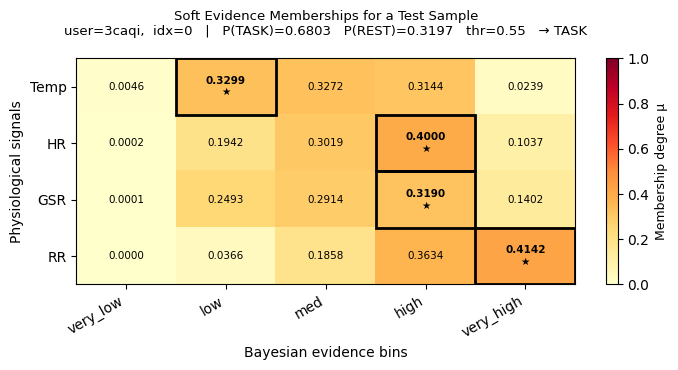

[saved] C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_sample_soft_memberships.png
[saved] C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\sample_soft_memberships.csv


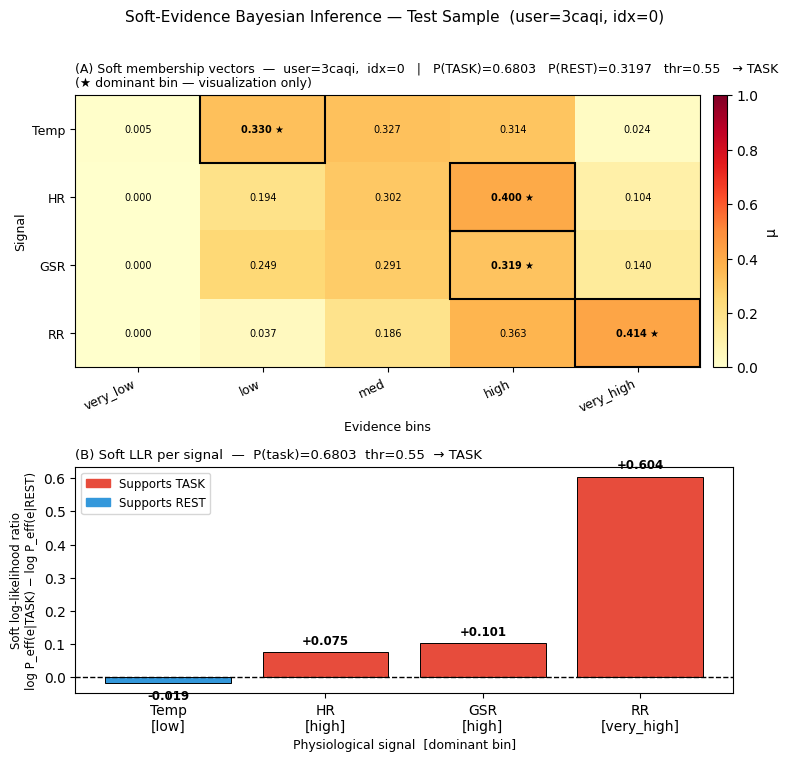

[saved] C:\Users\doqua\fuzzy-bayesian-cognitive-load\fts-anfis-bns-final\artifacts\A2_soft_exp1\figures_4_2\fig_sample_soft_evidence_trace_combined.png


In [14]:
"""
Figure 4.6 — Soft Evidence Membership Heatmap.

Visualizes the Gaussian-kernel membership vector μ_{s,b}(p_s) for each
physiological signal over all Bayesian evidence bins.  This is the actual
input to soft-evidence Bayesian inference — NOT hard-bin assignment.

The dominant bin (★) is for visualization only; inference uses the full
membership vector via:

    P_eff(e_s | C=c) = Σ_b  μ_{s,b}(p_s) · P(E_s=b | C=c)
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Rectangle
from pathlib import Path
import json as _json

# Reload guard (cell can run standalone after %run main.py)
try:
    bn_details
except NameError:
    _ROOT = Path.cwd().resolve()
    if _ROOT.name == "notebooks":
        _ROOT = _ROOT.parent
    with open(_ROOT / "artifacts" / "A2_soft_exp1" / "bn_details.json", encoding="utf-8") as _f:
        bn_details = _json.load(_f)
    print("[reload] bn_details loaded from artifact JSON")

try:
    signals
except NameError:
    signals = bn_details["bn_structure"]["evidence_nodes"]

try:
    FIG_DIR
except NameError:
    _ROOT = Path.cwd().resolve()
    if _ROOT.name == "notebooks":
        _ROOT = _ROOT.parent
    FIG_DIR = _ROOT / "artifacts" / "A2_soft_exp1" / "figures_4_2"
    FIG_DIR.mkdir(parents=True, exist_ok=True)


def plot_sample_soft_memberships(
    bn_details: dict,
    signals: list,
    fig_dir,
    filename: str = "fig_sample_soft_memberships.png",
):
    """
    Plot a heatmap of soft-evidence membership vectors for a test sample.

    Parameters
    ----------
    bn_details : dict   Loaded bn_details.json artifact.
    signals    : list   Ordered list of signal names, e.g. ['Temp', 'HR', 'GSR', 'RR'].
    fig_dir    : Path   Output directory for figure and CSV.
    filename   : str    Output PNG filename.
    """
    trace = bn_details["sample_inference_trace"]

    # --- strict mode guard ---
    if trace.get("mode") != "soft":
        raise RuntimeError(
            f"Expected soft trace, got mode={trace.get('mode')!r}. "
            "Regenerate bn_details.json after fixing BNFusion.explain_sample()."
        )

    sm = trace.get("soft_memberships")
    if not sm:
        raise RuntimeError(
            "soft_memberships not found in sample_inference_trace. "
            "Please rerun main.py with A2_soft and regenerate bn_details.json."
        )

    # Bin order: prefer artifact, fallback to canonical order
    bin_names = (
        bn_details["bn_structure"].get("bin_names")
        or ["very_low", "low", "med", "high", "very_high"]
    )

    sample_idx  = trace.get("sample_index", 0)
    user_id     = trace.get("user_id", "unknown")
    post_task   = trace.get("final_posterior_task")
    threshold   = bn_details.get("threshold")
    post_rest   = (1.0 - post_task) if post_task is not None else None
    predicted   = ("TASK" if post_task >= threshold else "REST") if (post_task is not None and threshold is not None) else "?"

    # Build membership matrix (n_signals × n_bins)
    M = np.array([[sm[s][b] for b in bin_names] for s in signals])

    # ---------------------------------------------------------------
    # Figure — heatmap
    # ---------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(7.2, 3.8))
    im = ax.imshow(M, aspect="auto", vmin=0.0, vmax=1.0, cmap="YlOrRd")

    ax.set_xticks(np.arange(len(bin_names)))
    ax.set_xticklabels(bin_names, rotation=30, ha="right", fontsize=10)
    ax.set_yticks(np.arange(len(signals)))
    ax.set_yticklabels(signals, fontsize=10)

    # Annotate values; highlight dominant bin per signal
    for i in range(len(signals)):
        j_max = int(np.argmax(M[i]))
        for j in range(len(bin_names)):
            val = M[i, j]
            is_max = (j == j_max)
            text_color = "white" if val > 0.55 else "black"
            label = f"{val:.4f}\n★" if is_max else f"{val:.4f}"
            ax.text(
                j, i, label,
                ha="center", va="center",
                fontsize=7.5,
                fontweight="bold" if is_max else "normal",
                color=text_color,
            )
        # Black border around dominant cell
        ax.add_patch(Rectangle(
            (j_max - 0.5, i - 0.5), 1, 1,
            fill=False, edgecolor="black", linewidth=2.0, zorder=3,
        ))

    # Build title lines
    line1 = "Soft Evidence Memberships for a Test Sample"
    line2 = f"user={user_id},  idx={sample_idx}"
    if post_task is not None:
        line2 += f"   |   P(TASK)={post_task:.4f}   P(REST)={post_rest:.4f}   thr={threshold:.2f}   → {predicted}"
    line3 = ""

    ax.set_title(f"{line1}\n{line2}\n{line3}", fontsize=9.5)
    ax.set_xlabel("Bayesian evidence bins", fontsize=10)
    ax.set_ylabel("Physiological signals", fontsize=10)

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Membership degree μ", fontsize=9)

    fig.tight_layout()
    out_path = fig_dir / filename
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"[saved] {out_path}")

    # ---------------------------------------------------------------
    # Save CSV
    # ---------------------------------------------------------------
    df_sm = pd.DataFrame(M, columns=bin_names)
    df_sm.insert(0, "Signal", signals)
    df_sm["Dominant_bin"]         = [bin_names[int(np.argmax(row))] for row in M]
    df_sm["Dominant_membership"]  = [float(np.max(row)) for row in M]

    csv_path = fig_dir / "sample_soft_memberships.csv"
    df_sm.to_csv(csv_path, index=False)
    print(f"[saved] {csv_path}")

    return fig, M, bin_names


# Run standalone figure
fig_sm, M, bin_names_sm = plot_sample_soft_memberships(
    bn_details, signals, FIG_DIR
)

# ---------------------------------------------------------------
# Optional: Combined 2-panel figure (heatmap + LLR bar chart)
# ---------------------------------------------------------------
trace    = bn_details["sample_inference_trace"]
bn_struct = bn_details["bn_structure"]
sw        = bn_details.get("signal_weights", {s: 1.0 for s in signals})
cpt       = bn_details["cpt_tables"]
prior     = bn_details["prior"]

contributions = {sig: trace["log_likelihood_ratio"][sig] for sig in signals}
dom_bins      = trace.get("dominant_bins", trace.get("evidence_bins", {}))
sm_data       = trace["soft_memberships"]

sample_idx = trace.get("sample_index", 0)
user_id    = trace.get("user_id", "unknown")
threshold  = bn_details["threshold"]
post_task  = trace["final_posterior_task"]
post_rest  = 1.0 - post_task
predicted  = "TASK" if post_task >= threshold else "REST"

fig2, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(8, 7.5),
    gridspec_kw={"height_ratios": [1.2, 1]},
)

# --- Panel A: membership heatmap ---
im2 = ax_top.imshow(M, aspect="auto", vmin=0.0, vmax=1.0, cmap="YlOrRd")
ax_top.set_xticks(np.arange(len(bin_names_sm)))
ax_top.set_xticklabels(bin_names_sm, rotation=25, ha="right", fontsize=9)
ax_top.set_yticks(np.arange(len(signals)))
ax_top.set_yticklabels(signals, fontsize=9)

for i in range(len(signals)):
    j_max = int(np.argmax(M[i]))
    for j in range(len(bin_names_sm)):
        val = M[i, j]
        is_max = (j == j_max)
        tc = "white" if val > 0.55 else "black"
        ax_top.text(j, i, f"{val:.3f}" + (" ★" if is_max else ""),
                    ha="center", va="center", fontsize=7,
                    fontweight="bold" if is_max else "normal", color=tc)
    ax_top.add_patch(Rectangle(
        (j_max - 0.5, i - 0.5), 1, 1,
        fill=False, edgecolor="black", linewidth=1.5, zorder=3,
    ))

fig2.colorbar(im2, ax=ax_top, label="μ", fraction=0.03, pad=0.02)
ax_top.set_title(
    f"(A) Soft membership vectors  —  user={user_id},  idx={sample_idx}"
    f"   |   P(TASK)={post_task:.4f}   P(REST)={post_rest:.4f}   thr={threshold:.2f}   → {predicted}\n"
    f"(★ dominant bin — visualization only)",
    fontsize=9.0, loc="left",
)
ax_top.set_xlabel("Evidence bins", fontsize=9)
ax_top.set_ylabel("Signal", fontsize=9)

# --- Panel B: LLR bar chart ---
vals   = [contributions[s] for s in signals]
lbls   = [f"{s}\n[{dom_bins.get(s,'')}]" for s in signals]
colors = ["#e74c3c" if v > 0 else "#3498db" for v in vals]

bars = ax_bot.bar(lbls, vals, color=colors, edgecolor="black", linewidth=0.7)
ax_bot.axhline(0, color="black", linewidth=1.0, linestyle="--")

for bar, val in zip(bars, vals):
    y_pos = val + 0.015 if val >= 0 else val - 0.06
    ax_bot.text(bar.get_x() + bar.get_width() / 2, y_pos,
                f"{val:+.3f}", ha="center", va="bottom",
                fontsize=8.5, fontweight="bold")

ax_bot.set_ylabel(
    "Soft log-likelihood ratio\nlog P_eff(e|TASK) − log P_eff(e|REST)",
    fontsize=8.5,
)
ax_bot.set_xlabel("Physiological signal  [dominant bin]", fontsize=9)
ax_bot.set_title(
    f"(B) Soft LLR per signal  —  P(task)={post_task:.4f}  "
    f"thr={threshold:.2f}  → {predicted}",
    fontsize=9.5, loc="left",
)
patch_t = mpatches.Patch(color="#e74c3c", label="Supports TASK")
patch_r = mpatches.Patch(color="#3498db", label="Supports REST")
ax_bot.legend(handles=[patch_t, patch_r], fontsize=8.5)

fig2.suptitle(
    f"Soft-Evidence Bayesian Inference — Test Sample  (user={user_id}, idx={sample_idx})",
    fontsize=11, y=1.01,
)
fig2.tight_layout()
combined_path = FIG_DIR / "fig_sample_soft_evidence_trace_combined.png"
fig2.savefig(combined_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[saved] {combined_path}")


---
## Phần 6 — Figure: ANFIS Rule Importance Heatmap

In [ ]:
"""
Phần 6: ANFIS Rule Importance Heatmap.
Phân tích các luật TSK học được từ file anfis_rules.json.

Mỗi luật có dạng:
  Ri: IF <feature> is Gauss(c=..., σ=...) AND ... THEN y = coef*<feature> + ...

Tính tổng |coefficient| của mỗi feature trên tất cả rule của signal đó.
Features là các transition probability của FTS: P(L|L), P(M|L), ..., P(H|H)
"""

# Tất cả feature name có thể xuất hiện (FTS 3-set, 9 features)
FEATURE_NAMES = [
    "P(L|L)", "P(M|L)", "P(H|L)",
    "P(L|M)", "P(M|M)", "P(H|M)",
    "P(L|H)", "P(M|H)", "P(H|H)",
]

# ---------------------------------------------------------------
# Parser: trích feature và coefficient từ dòng THEN
# ---------------------------------------------------------------
_coef_re = re.compile(
    r"([+-]?\s*\d+\.\d+)\*P\(([LMH])\|([LMH])\)"
)

def parse_rule_consequent(rule_str: str) -> dict:
    """
    Trích các cặp (feature_name, coefficient) từ phần THEN của rule string.
    Ví dụ: "THEN y = 0.1172*P(M|L) + ..."
    Trả về dict: {'P(M|L)': 0.1172, ...}
    """
    # Lấy phần sau THEN
    if "THEN" not in rule_str:
        return {}
    then_part = rule_str.split("THEN")[1]
    result = {}
    for match in _coef_re.finditer(then_part):
        coef_str, state, given = match.groups()
        coef = float(coef_str.replace(" ", ""))
        feat = f"P({state}|{given})"
        # Tổng hợp nếu feature xuất hiện nhiều lần trong rule
        result[feat] = result.get(feat, 0.0) + coef
    return result

# ---------------------------------------------------------------
# Tính importance matrix (signal x feature)
# ---------------------------------------------------------------
importance = {}
for sig in signals:
    if sig not in anfis_rules:
        importance[sig] = {f: 0.0 for f in FEATURE_NAMES}
        continue
    sig_importance = {f: 0.0 for f in FEATURE_NAMES}
    for rule_str in anfis_rules[sig]:
        coefs = parse_rule_consequent(rule_str)
        for feat, coef in coefs.items():
            if feat in sig_importance:
                sig_importance[feat] += abs(coef)   # tổng |coefficient|
    importance[sig] = sig_importance

df_imp = pd.DataFrame(importance, index=FEATURE_NAMES).T   # (signals x features)
df_imp.index.name = "Signal"
df_imp.columns.name = "FTS_feature"

print("ANFIS feature importance (sum |coef|):")
print(df_imp.round(4))

# Lưu CSV
csv_imp = FIG_DIR / "anfis_rule_importance.csv"
df_imp.to_csv(csv_imp)
print(f"[saved] {csv_imp}")

# ---------------------------------------------------------------
# Vẽ heatmap importance
# ---------------------------------------------------------------
mat_imp = df_imp.values.astype(float)  # (4, 9)
vmax_imp = mat_imp.max() if mat_imp.max() > 0 else 1.0

fig, ax = plt.subplots(figsize=(11, 4))
im2 = ax.imshow(mat_imp, cmap="YlOrRd", vmin=0, vmax=vmax_imp, aspect="auto")

ax.set_xticks(range(len(FEATURE_NAMES)))
ax.set_xticklabels(FEATURE_NAMES, fontsize=9, rotation=30, ha="right")
ax.set_yticks(range(len(signals)))
ax.set_yticklabels(signals, fontsize=10)
ax.set_xlabel("Đặc trưng chuyển trạng thái FTS  P(state|given)", fontsize=9)
ax.set_ylabel("Tín hiệu sinh lý", fontsize=9)
ax.set_title(
    "Mức độ quan trọng của đặc trưng FTS trong luật ANFIS học được\n"
    "Giá trị = tổng |hệ số| trên toàn bộ luật của tín hiệu",
    fontsize=10
)

# Annotate
for i in range(mat_imp.shape[0]):
    for j in range(mat_imp.shape[1]):
        val = mat_imp[i, j]
        color = "white" if val > 0.65 * vmax_imp else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                fontsize=8, color=color)

plt.colorbar(im2, ax=ax, label="Σ |coef|")
fig.tight_layout()
out_path = FIG_DIR / "fig_anfis_rule_importance.png"
fig.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"[saved] {out_path}")

---
## Phần 7 — Figure captions (đề xuất cho khóa luận)

| Hình | Caption tiếng Việt |
|------|-------------------|
| Hình 4.x | **Cấu trúc Bayesian Network Fusion trong thực nghiệm 1.** Nút gốc CL đại diện cho nhãn tải nhận thức (cognitive load) với hai trạng thái: *rest* và *task*. Bốn nút evidence (Temp, HR, GSR, RR) là các tín hiệu sinh lý được rời rạc hóa thành 5 bin theo phân vị. Xác suất tiên nghiệm P(rest) ≈ P(task) ≈ 0.5 cho thấy dữ liệu gần cân bằng lớp. |
| Hình 4.x | **Mức độ ủng hộ lớp task/rest của từng evidence bin thông qua log-likelihood ratio từ CPT.** Giá trị LLR(s,b) = log P(b\|task) − log P(b\|rest) dương (đỏ) biểu thị bin b ủng hộ trạng thái *task*; âm (xanh) biểu thị ủng hộ *rest*. RR và HR cho thấy xu hướng rõ rệt nhất: bin *very_high* ủng hộ mạnh *task* trong khi *very_low* ủng hộ *rest*. |
| Hình 4.x | **Phân phối CPT thô P(bin\|class) cho từng tín hiệu.** Mỗi biểu đồ grouped bar cho thấy xác suất của từng bin với hai lớp REST và TASK. Sự chênh lệch giữa hai cột trong cùng bin phản ánh độ phân biệt của tín hiệu đó. |
| Hình 4.5 | **Truy vết suy luận Bayesian theo soft evidence trên một mẫu kiểm thử.** Mỗi tín hiệu được biểu diễn bằng vector membership trên năm bin xác suất ANFIS; bin trội nhất chỉ được dùng để trực quan hóa. Các cột biểu diễn soft log-likelihood ratio giữa lớp TASK và REST, $\text{LLR}(s) = w_s \log P_\text{eff}(e_s\mid\text{TASK}) - w_s \log P_\text{eff}(e_s\mid\text{REST})$, trong đó $P_\text{eff}(e_s\mid C) = \sum_b \mu_{s,b}(p_s)\,P(E_s{=}b\mid C)$. Thanh đỏ (dương) ủng hộ *task*; thanh xanh (âm) ủng hộ *rest*. Posterior cuối cùng P(task) vượt ngưỡng threshold, cho kết quả dự đoán đúng lớp. |
| Hình 4.x | **Mức độ quan trọng của các đặc trưng chuyển trạng thái FTS trong các luật ANFIS học được.** Giá trị trong mỗi ô là tổng trị tuyệt đối của hệ số TSK tương ứng trên toàn bộ luật của tín hiệu đó. Các đặc trưng có giá trị cao (màu đậm) đóng vai trò chính trong việc phân biệt tải nhận thức thông qua ANFIS. |

---
## Tổng kết — Danh sách file đã lưu


In [ ]:
"""
Phần cuối: In danh sách tất cả file đã lưu trong figures_4_2/
"""
print("=" * 60)
print("Danh sách file đã tạo trong", FIG_DIR)
print("=" * 60)
saved_files = sorted(FIG_DIR.glob("*"))
for f in saved_files:
    size_kb = f.stat().st_size / 1024
    print(f"  {f.name:<45}  {size_kb:>7.1f} KB")